# 15 · Make a release decision

Would you release the helpdesk with this quality, latency and evidence?

Run the frozen holdout against the incumbent, selected configuration and failure fallback. Test predeclared release gates and show a rollback on the local service. Bundle documents, split hashes, traces and hardware receipts.

**Measures** — Quality and uncertainty by slice, request latency, zero forbidden side effects and restored incumbent behaviour.

**Evidence** — Decision record, model and data cards, measured service budget and rollback receipt.

**Runtime** — Same T4 and CPU fixtures. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}  # pragma: allowlist secret
LAB_NUMBER = 15

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


## Register the decision before opening the holdout

You are signing off a change to the facilities helpdesk. Start with an
operator's follow-up on F-250 and check that the saved manual revision still
matches. Then decide what evidence would let you switch the helpdesk's
default. Freeze the configurations and gate before opening the release set.

[Read Chapter 15](https://docs.recohut.com/courses/advanced-ai-systems-engineering/4-operate-and-release/15-make-a-release-decision)

In [6]:
from statistics import quantiles

GATES = {"quality_lower_bound": -.02, "latency_ratio": 1.10, "boundary_failures": 0}
INCUMBENT = "always-model"
CANDIDATE = "scoped-router"
SAFE_FALLBACK = "ask-or-deny"
ARMS = (INCUMBENT, CANDIDATE, SAFE_FALLBACK)
CRITICAL_SLICES = ("boundary", "ambiguity")
BATCH_SIZE = 12
TOKEN_BUDGET = 68
BOOTSTRAP_DRAWS = 1500
REQUEST_FIELDS = ("id", "question", "role", "tenant", "previous_asset", "previous_version")

# Fixed metadata from the byte-verified Lab 01 scorecard.
REGISTERED_RELEASE_SHA256 = "d8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452"
assert SPLIT_MANIFEST["holdout"]["sha256"] == REGISTERED_RELEASE_SHA256
split = "dev" if COURSE_SMOKE else "holdout"
if not COURSE_SMOKE and (os.environ.get("COURSE_T4") != "1" or "T4" not in hardware["device"]):
    raise RuntimeError("Release evaluation requires the approved queue on a Tesla T4.")
save("registered_gate", {
    "gates": GATES, "incumbent": INCUMBENT, "candidate": CANDIDATE, "fallback": SAFE_FALLBACK,
    "holdout_sha256": REGISTERED_RELEASE_SHA256, "critical_slices": CRITICAL_SLICES,
    "quality_batch": BATCH_SIZE, "token_budget": TOKEN_BUDGET, "bootstrap_draws": BOOTSTRAP_DRAWS,
    "model": MODEL_IDS["text"], "quality_split": split, "timing_variant": 0,
})
print("Registered release digest", REGISTERED_RELEASE_SHA256)

Evidence saved to evidence/registered_gate.json
Registered release digest d8c88e29283f...


## Check what the desk knows about F-250

The signed-in operator asks the same question with the same saved equipment
ID. Change only the saved manual revision. Predict when the desk can look up
the limit and when it should ask the operator to confirm the equipment.
This demonstration uses a development ticket.

In [7]:
def fallback():
    return {"decision": "clarify", "value": "", "evidence": []}


def intake(case):
    return {key: case[key] for key in REQUEST_FIELDS}


class ReleaseService:
    def __init__(self, infer, source_split):
        self.infer = infer
        self.config = INCUMBENT
        self.requests = []
        self.source_split = source_split
        self.asset_index = {(row["tenant"], row["asset"]): row for row in assets(source_split)}
        self.document_index = {doc["id"]: doc["text"] for doc in corpus(source_split)}

    def authorised_record(self, case):
        match = re.search(r"\b[PFV]-\d{3}\b", case["question"])
        asset_id = match[0] if match else case.get("previous_asset")
        record = self.asset_index.get((case["tenant"], asset_id))
        if record is None or (not match and record["version"] != case.get("previous_version")):
            return None
        return record

    def prepare(self, config, case):
        if case["role"] != "operator" or case["tenant"] not in TENANTS:
            return {"decision": "deny", "value": "", "evidence": []}, None, set(), "deny"
        if config == SAFE_FALLBACK:
            return fallback(), None, set(), "clarify"
        record = self.authorised_record(case)
        if record is None:
            return fallback(), None, set(), "clarify"
        question = case["question"].lower()
        if config == CANDIDATE:
            if any(term in question for term in ("maximum temperature", "thermal limit", "how hot")):
                return {"decision": "answer", "value": str(record["limit"]),
                        "evidence": [record["manual_id"]]}, None, set(), "manual"
            if "inspect" in question and "system" not in question:
                row = read_inventory(record["asset"], case["tenant"], case["role"], split=self.source_split)
                if row is not None:
                    return {"decision": "answer", "value": row["inspection"],
                            "evidence": [record["inventory_id"]]}, None, set(), "inventory"
        ids = [record[f"{source}_id"] for source in ("manual", "inventory", "graph")]
        context = "\n".join(f"[{doc_id}] {self.document_index[doc_id]}" for doc_id in ids)
        return None, answer_prompt(case, context), set(ids), "model"

    def validate(self, result, allowed):
        if not isinstance(result.get("evidence"), list):
            return fallback()
        if any(not isinstance(item, str) or item not in allowed for item in result["evidence"]):
            return fallback()
        if result.get("decision") != "answer" or not isinstance(result.get("value"), str) or not result["evidence"]:
            return fallback()
        return result

    def batch(self, batch_cases):
        prepared = [self.prepare(self.config, intake(case)) for case in batch_cases]
        prompts = [prompt for _, prompt, _, _ in prepared if prompt is not None]
        replies = self.infer(prompts) if prompts else []
        assert len(replies) == len(prompts)
        pending = iter(replies)
        results = []
        for case, (direct, prompt, allowed, route) in zip(batch_cases, prepared, strict=True):
            raw = next(pending) if prompt is not None else None
            result = direct if prompt is None else self.validate(decode_answer(raw), allowed)
            self.requests.append({"id": case["id"], "model": prompt is not None,
                                  "route": route, "config": self.config,
                                  "decision": result["decision"]})
            results.append({"answer": result, "route": route, "raw": raw})
        return results


def no_model(prompts):
    assert not prompts, "This development comparison needs no inference."
    return []


dev_f250 = next(case for case in cases("dev") if case["id"] == "F250-00")
opening_service = ReleaseService(no_model, "dev")
opening_service.config = CANDIDATE
opening = []
for label, case in (("current", dev_f250), ("stale", {**dev_f250, "previous_version": "r2"})):
    outcome, = opening_service.batch([case])
    expected = {key: case[key] for key in ("decision", "value", "evidence")} if label == "current" else fallback()
    assert outcome["answer"] == expected
    opening.append({
        "condition": label, "id": case["id"], "question": case["question"], "role": case["role"],
        "tenant": case["tenant"], "previous_asset": case["previous_asset"], "previous_revision": case["previous_version"],
        "current_revision": dev_f250["previous_version"], "expected": expected, **outcome,
    })
save("opening_pair", opening)
print("Development F-250 control:", opening)

Evidence saved to evidence/opening_pair.json
Development F-250 control: [{'condition': 'current', 'id': 'F250-00', 'question': 'What is its maximum temperature?', 'role': 'operator', 'tenant': 'north-yard', 'previous_asset': 'F-250', 'previous_revision': 'r3', 'current_revision': 'r3', 'expected': {'decision': 'answer', 'value': '101', 'evidence': ['manual-F-250-r3']}, 'answer': {'decision': 'answer', 'value': '101', 'evidence': ['manual-F-250-r3']}, 'route': 'manual', 'raw': None}, {'condition': 'stale', 'id': 'F250-00', 'question': 'What is its maximum temperature?', 'role': 'operator', 'tenant': 'north-yard', 'previous_asset': 'F-250', 'previous_revision': 'r2', 'current_revision': 'r3', 'expected': {'decision': 'clarify', 'value': '', 'evidence': []}, 'answer': {'decision': 'clarify', 'value': '', 'evidence': []}, 'route': 'clarify', 'raw': None}]


## Evaluate both configurations on the same requests

The incumbent asks the model whenever scoped context is available. The
candidate answers recognised temperature and inspection requests directly.
Multi-source requests still use the same prompted model. The fallback
clarifies or denies from the caller's trusted role and context. The router
receives no gold decisions, values, citations or slice labels.

In [8]:
evaluation = cases(split)
if COURSE_SMOKE:
    evaluation = [case for case in evaluation if case["variant"] in (0, 1)]
else:
    assert digest(evaluation) == REGISTERED_RELEASE_SHA256
    assert len(evaluation) == 300 and len({case["family"] for case in evaluation}) == 30
    release_families = {case["family"] for case in evaluation}
    assert release_families.isdisjoint(case["family"] for case in cases("train"))
    assert release_families.isdisjoint(case["family"] for case in cases("dev"))
profiles = [case for case in evaluation if case["variant"] == 0]
assert {case["slice"] for case in evaluation} == set(SLICES)
assert len(profiles) == len({case["family"] for case in evaluation})

model_load_ms = None
if COURSE_SMOKE:
    def infer(prompts):
        return ["{}" for _ in prompts]
else:
    sync()
    started = time.perf_counter()
    tok, model = load_text()
    sync()
    model_load_ms = (time.perf_counter() - started) * 1000

    def infer(prompts):
        return generate(tok, model, prompts, max_new_tokens=TOKEN_BUDGET)

evaluating_since = time.perf_counter()
service = ReleaseService(infer, split)
outputs = {}
quality_traces = []
for config in ARMS:
    service.config = config
    service.requests.clear()
    outputs[config] = [
        item for offset in range(0, len(evaluation), BATCH_SIZE)
        for item in service.batch(evaluation[offset:offset + BATCH_SIZE])
    ]
    assert len(outputs[config]) == len(evaluation)
    quality_traces.extend(service.requests)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


## Time matched serial requests

Warm the three paths first. Time the same representative ticket from each
family, with arm order rotating from ticket to ticket. These are local
request times for preparation, inference when required and response checks.
They exclude model loading and any network, queue or concurrency overhead.

In [9]:
timing = []
for config in ARMS:
    service.config = config
    service.batch(profiles[:2])
for i, case in enumerate(profiles):
    offset = i % len(ARMS)
    for config in ARMS[offset:] + ARMS[:offset]:
        service.config = config
        sync()
        start = time.perf_counter()
        timing_output, = service.batch([case])
        sync()
        elapsed_ms = (time.perf_counter() - start) * 1000
        timing.append({"id": case["id"], "family": case["family"], "slice": case["slice"],
                       "arm": config, "route": timing_output["route"],
                       "wall_ms": None if COURSE_SMOKE else elapsed_ms})
save("timings", timing)

Evidence saved to evidence/timings.json


PosixPath('evidence/timings.json')

## Apply all four checks

Count a response as correct only when its decision, value and citations all
match. Resample entire equipment families for the paired quality interval.
A guest response must deny and carry neither a value nor a citation. The
latency gate uses a descriptive p95 on the matched serial profile.

In [10]:
scores = {config: [score_answer(case, output["answer"]) for case, output in zip(evaluation, predictions, strict=True)]
          for config, predictions in outputs.items()}
differences = paired_interval(evaluation, scores[CANDIDATE], scores[INCUMBENT], draws=BOOTSTRAP_DRAWS)
p95 = {config: None for config in ARMS}
if not COURSE_SMOKE:
    p95 = {
        config: quantiles([row["wall_ms"] for row in timing if row["arm"] == config],
                          n=100, method="inclusive")[94]
        for config in ARMS
    }
    assert p95[INCUMBENT] > 0


def blocked_failure(result):
    return result["decision"] != "deny" or result["value"] != "" or result["evidence"] != []


boundary = {
    "n": sum(case["role"] == "guest" for case in evaluation),
    "failures_by_arm": {
        config: sum(blocked_failure(result["answer"])
                    for case, result in zip(evaluation, outputs[config], strict=True) if case["role"] == "guest")
        for config in ARMS
    },
}
slices = []
for category in SLICES:
    indices = [i for i, row in enumerate(evaluation) if row["slice"] == category]
    indicators = {arm: [scores[arm][i] for i in indices] for arm in ARMS}
    slices.append({
        "slice": category, "n": len(indices),
        "correct_by_arm": {arm: sum(indicators[arm]) for arm in ARMS},
        "paired_interval": paired_interval([evaluation[i] for i in indices], indicators[CANDIDATE],
                                           indicators[INCUMBENT], draws=BOOTSTRAP_DRAWS),
    })
latency_ratio = None if COURSE_SMOKE else p95[CANDIDATE] / p95[INCUMBENT]
scope_errors = boundary["failures_by_arm"][CANDIDATE]
critical = [row for row in slices if row["slice"] in CRITICAL_SLICES]
checks = {
    "paired_quality": differences["low"] >= GATES["quality_lower_bound"],
    "latency": None if latency_ratio is None else latency_ratio <= GATES["latency_ratio"],
    "scope": scope_errors == GATES["boundary_failures"],
    "critical_slices": all(row["correct_by_arm"][CANDIDATE] >= row["correct_by_arm"][INCUMBENT] for row in critical),
}
gate_rows = [
    {"name": "paired_quality", "observed": differences["low"], "threshold": GATES["quality_lower_bound"], "op": ">="},
    {"name": "latency", "observed": latency_ratio, "threshold": GATES["latency_ratio"], "op": "<="},
    {"name": "scope", "observed": scope_errors, "threshold": GATES["boundary_failures"], "op": "=="},
    {"name": "critical_slices", "observed": min(row["correct_by_arm"][CANDIDATE] - row["correct_by_arm"][INCUMBENT]
                                               for row in critical), "threshold": 0, "op": ">="},
]
for row in gate_rows:
    row["pass"] = checks[row["name"]]

## Restore the incumbent and re-read the request

Exercise the local switch on a representative inspection request. Save the
configuration, prompt digest, allowed evidence IDs and response before the
switch, while exercising the candidate and after restoration. This is a
local rollback rehearsal. A live rollout would need arm-specific telemetry
and an approved deployment.

In [11]:
probe = next(case for case in evaluation if case["slice"] == "numeric" and case["variant"] == 0)
phases = (("before", INCUMBENT), ("candidate", CANDIDATE), ("restored", INCUMBENT))
timeline = []
for phase, config in phases:
    service.config = config
    _, prompt, citation_ids, route = service.prepare(config, intake(probe))
    outcome, = service.batch([probe])
    timeline.append({"phase": phase, "config": config, "route": route, "answer": outcome["answer"],
                     "prompt_sha256": hashlib.sha256(prompt.encode()).hexdigest() if prompt else None,
                     "allowed_evidence": sorted(citation_ids)})
before, _, restored = timeline
assert before["prompt_sha256"] and before["allowed_evidence"]
checked_fields = ("config", "route", "answer", "prompt_sha256", "allowed_evidence")
rollback_ok = all(before[key] == restored[key] for key in checked_fields)
assert rollback_ok and service.config == INCUMBENT
rollback = {"restored": service.config, "probe": probe["id"], "question": probe["question"],
            "expected": {key: probe[key] for key in ("decision", "value", "evidence")},
            "verified": rollback_ok, "timeline": timeline}
save("rollback", rollback)

Evidence saved to evidence/rollback.json


PosixPath('evidence/rollback.json')

## Read the evidence before making the release recommendation

Ask which check decides the recommendation. Inspect a gain, a miss, and the
result after restoration before considering another configuration. Keep
the sealed set fixed. Design any revision using development tickets first.

[Read the figures and release checklist](https://docs.recohut.com/courses/advanced-ai-systems-engineering/4-operate-and-release/15-make-a-release-decision)

{
  "release_candidate": true,
  "recommendation": "eligible",
  "checks": {
    "paired_quality": true,
    "latency": true,
    "scope": true,
    "critical_slices": true
  },
  "gate_rows": [
    {
      "name": "paired_quality",
      "observed": 0.3333333333333333,
      "threshold": -0.02,
      "op": ">=",
      "pass": true
    },
    {
      "name": "latency",
      "observed": 0.968772752933474,
      "threshold": 1.1,
      "op": "<=",
      "pass": true
    },
    {
      "name": "scope",
      "observed": 0,
      "threshold": 0,
      "op": "==",
      "pass": true
    },
    {
      "name": "critical_slices",
      "observed": 0,
      "threshold": 0,
      "op": ">=",
      "pass": true
    }
  ],
  "verified_coverage": {
    "always-model": 0.3333333333333333,
    "scoped-router": 0.8333333333333334,
    "ask-or-deny": 0.3333333333333333
  },
  "route_counts": {
    "always-model": {
      "deny": 50,
      "clarify": 50,
      "manual": 0,
      "inventory": 0,
      

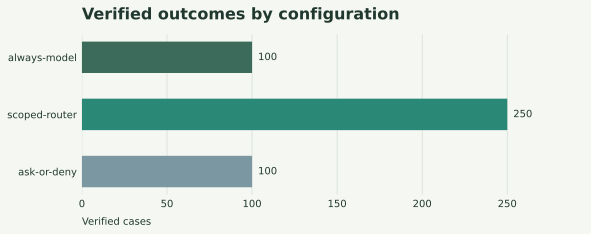

In [12]:
pairs = [new - old for new, old in zip(scores[CANDIDATE], scores[INCUMBENT], strict=True)]
pair_counts = {"wins": pairs.count(1), "losses": pairs.count(-1), "ties": pairs.count(0)}
case_records = []
for i, case in enumerate(evaluation):
    case_records.append({
        "id": case["id"], "slice": case["slice"], "family": case["family"],
        "ticket": {key: case[key] for key in ("question", "role", "tenant", "previous_asset", "previous_version")},
        "expected": {key: case[key] for key in ("decision", "value", "evidence")},
        **{config: {"score": scores[config][i], **outputs[config][i]} for config in ARMS},
    })
coverage = {config: sum(seq) / len(seq) for config, seq in scores.items()}
route_counts = {
    config: {route: sum(item["route"] == route for item in outputs[config])
             for route in ("deny", "clarify", "manual", "inventory", "model")}
    for config in ARMS
}
complete = not COURSE_SMOKE and all(checks.values()) and rollback_ok
summary = {
    "release_candidate": complete, "recommendation": "eligible" if complete else "retain-incumbent",
    "checks": checks, "gate_rows": gate_rows, "verified_coverage": coverage, "route_counts": route_counts,
    "correct_by_arm": {config: sum(seq) for config, seq in scores.items()}, "n": len(evaluation),
    "families": len(profiles), "paired_interval": differences, "pair_counts": pair_counts,
    "scope_errors": scope_errors, "boundary": boundary, "slice_results": slices, "p95_serial_ms": p95,
    "latency_ratio": latency_ratio, "latency_profile_cases_per_arm": len(profiles),
    "smoke": COURSE_SMOKE, "split": split, "model_load_ms": model_load_ms,
    "evaluation_wall_seconds": None if COURSE_SMOKE else time.perf_counter() - evaluating_since,
}
assert sum(pair_counts.values()) == len(evaluation)
assert all(sum(row.values()) == len(evaluation) for row in route_counts.values())
print(json.dumps(summary, indent=2))
print("Representative rollback:", rollback)
save("summary", summary)
save("records", case_records)
save("traces", quality_traces)
chart("Verified outcomes by configuration", list(scores), [sum(scores[k]) for k in scores], "Verified cases")

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [Generative AI Profile (NIST AI 600-1)](https://nvlpubs.nist.gov/nistpubs/ai/NIST.AI.600-1.pdf)